<a href="https://colab.research.google.com/github/denverkim/snw/blob/main/LAB2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 근무시간 분석

In [ ]:
import pandas as pd

# 1. 근태 로그 파일 읽기
file_lst = ['att1.csv', 'att2.csv', 'att3.csv']

for file in file_lst:
    df = pd.read_csv(file)

df = pd.read_csv("attendance.csv")

# 2. 출퇴근 시간을 datetime으로 변환
df["Check_in"] = pd.to_datetime(
    df["Date"] + " " + df["Check_in"].str.strip()
)
df["Check_out"] = pd.to_datetime(
    df["Date"] + " " + df["Check_out"].str.strip()
)

# 3. 근무 시간 계산 (시간 단위)
df["Work_hours"] = (
    df["Check_out"] - df["Check_in"]
).dt.total_seconds() / 3600

# 4. 직원별 평균 근무 시간 계산
result = (
    df.groupby("Name", as_index=False)["Work_hours"]
    .mean()
    .rename(columns={"Work_hours": "Avg_hours"})
)

# 5. 소수점 둘째 자리까지 반올림
result["Avg_hours"] = result["Avg_hours"].round(2)

# 6. 결과 파일 저장
result.to_csv(
    "staff_avg_hours.csv",
    index=False,
    encoding="utf-8-sig"
)

print(result)
print("staff_avg_hours.csv 저장 완료")

In [8]:
import pandas as pd

# 1. 근태 로그 파일 읽기

df = pd.read_csv("/content/attendance.csv")
df

,Name,Date,Check_in,Check_out
0,김철수,2023-01-01,09:00:00,17:00:00
1,김영희,2023-01-01,09:30:00,18:00:00
2,김철수,2023-01-02,08:45:00,17:15:00
3,김영희,2023-01-02,10:00:00,18:30:00
4,박지민,2023-01-01,09:00:00,17:30:00
5,김철수,2023-01-03,09:10:00,17:00:00


In [9]:
# 2. 출퇴근 시간을 datetime으로 변환

df["Check_in"] = pd.to_datetime(
    df["Date"] + " " + df["Check_in"].str.strip()
)

df["Check_out"] = pd.to_datetime(
    df["Date"] + " " + df["Check_out"].str.strip()
)
df

,Name,Date,Check_in,Check_out
0,김철수,2023-01-01,2023-01-01 09:00:00,2023-01-01 17:00:00
1,김영희,2023-01-01,2023-01-01 09:30:00,2023-01-01 18:00:00
2,김철수,2023-01-02,2023-01-02 08:45:00,2023-01-02 17:15:00
3,김영희,2023-01-02,2023-01-02 10:00:00,2023-01-02 18:30:00
4,박지민,2023-01-01,2023-01-01 09:00:00,2023-01-01 17:30:00
5,김철수,2023-01-03,2023-01-03 09:10:00,2023-01-03 17:00:00


In [10]:
# 3. 근무 시간 계산 (시간 단위)
df["Work_hours"] = (
    df["Check_out"] - df["Check_in"]
).dt.total_seconds() / 3600
df

,Name,Date,Check_in,Check_out,Work_hours
0,김철수,2023-01-01,2023-01-01 09:00:00,2023-01-01 17:00:00,8.000000
1,김영희,2023-01-01,2023-01-01 09:30:00,2023-01-01 18:00:00,8.500000
2,김철수,2023-01-02,2023-01-02 08:45:00,2023-01-02 17:15:00,8.500000
3,김영희,2023-01-02,2023-01-02 10:00:00,2023-01-02 18:30:00,8.500000
4,박지민,2023-01-01,2023-01-01 09:00:00,2023-01-01 17:30:00,8.500000
5,김철수,2023-01-03,2023-01-03 09:10:00,2023-01-03 17:00:00,7.833333


In [11]:
# 4. 직원별 평균 근무 시간 계산
result = (
    df.groupby("Name", as_index=False)["Work_hours"]
    .mean()
    .rename(columns={"Work_hours": "Avg_hours"})
)
result

,Name,Avg_hours
0,김영희,8.500000
1,김철수,8.111111
2,박지민,8.500000


In [12]:
# 5. 소수점 둘째 자리까지 반올림
result["Avg_hours"] = result["Avg_hours"].round(2)
result

,Name,Avg_hours
0,김영희,8.50
1,김철수,8.11
2,박지민,8.50


In [13]:
# 6. 결과 파일 저장
result.to_csv(
    "staff_avg_hours.csv",
    index=False,
    encoding="utf-8-sig"
)

In [14]:
print(result)
print("staff_avg_hours.csv 저장 완료")

  Name  Avg_hours
0  김영희       8.50
1  김철수       8.11
2  박지민       8.50
staff_avg_hours.csv 저장 완료


# 선그래프 연습

In [4]:
# 한글폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 27 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/

In [3]:
# 한글폰트 설정
import matplotlib.pyplot as plt

plt.rc('font', family='NanumBarunGothic')

/tmp/ipykernel_15550/3527103169.py:38: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) NanumBarunGothic.
  plt.tight_layout()


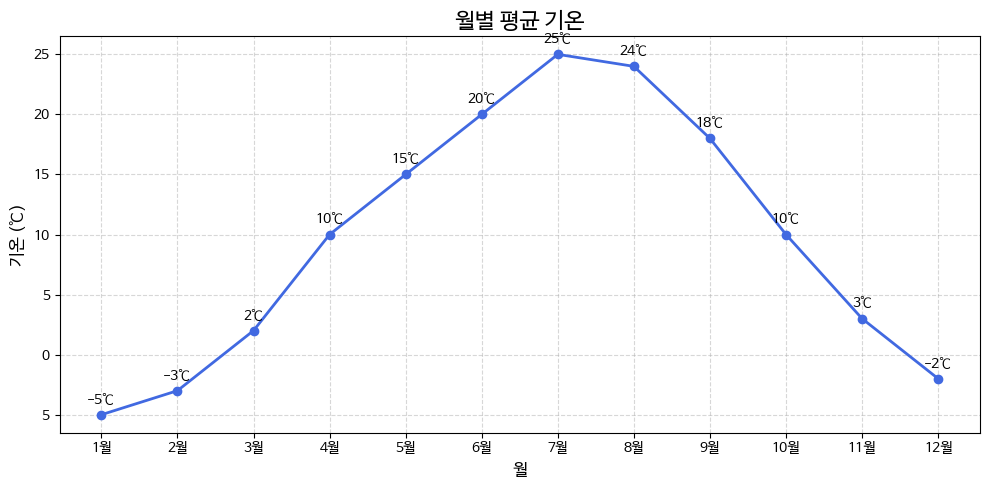

In [4]:
import matplotlib.pyplot as plt

# 월별 기온 데이터
months = [
    "1월", "2월", "3월", "4월", "5월", "6월",
    "7월", "8월", "9월", "10월", "11월", "12월"
]

temperatures = [-5, -3, 2, 10, 15, 20, 25, 24, 18, 10, 3, -2]

# 선그래프 생성
plt.figure(figsize=(10, 5))
plt.plot(
    months,
    temperatures,
    marker="o",
    color="royalblue",
    linewidth=2,
    markersize=6
)

# 그래프 제목 및 축 설정
plt.title("월별 평균 기온", fontsize=16)
plt.xlabel("월", fontsize=12)
plt.ylabel("기온 (℃)", fontsize=12)

# 각 데이터 값 표시
for month, temp in zip(months, temperatures):
    plt.annotate(
        str(temp) + "℃",
        (month, temp),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

# 그래프 표시
plt.show()